In [ ]:
# 查看当前挂载的数据集目录, 该目录下的变更重启环境后会自动还原
# View dataset directory. 
# This directory will be recovered automatically after resetting environment. 
!ls /home/aistudio/data

In [ ]:
# 查看工作区文件, 该目录下的变更将会持久保存. 请及时清理不必要的文件, 避免加载过慢.
# View personal work directory. 
# All changes under this directory will be kept even after reset. 
# Please clean unnecessary files in time to speed up environment loading. 
!ls /home/aistudio/work

In [1]:
# 如果需要进行持久化安装, 需要使用持久化路径, 如下方代码示例:
# If a persistence installation is required, 
# you need to use the persistence path as the following: 
#!mkdir /home/aistudio/external-libraries
#!pip install scikit-image -t /home/aistudio/external-libraries

In [1]:
# 同时添加如下代码, 这样每次环境(kernel)启动的时候只要运行下方代码即可: 
# Also add the following code, 
# so that every time the environment (kernel) starts, 
# just run the following code: 
import sys 
sys.path.append('/home/aistudio/external-libraries')

# example9-1 Roberts算子

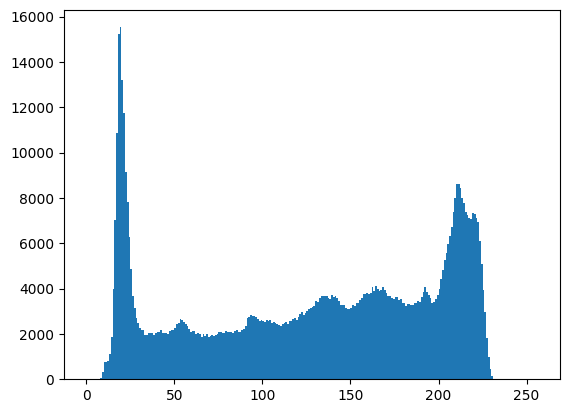

[[-1.  0.]
 [ 0.  1.]]
float64
[[ 0. -1.]
 [ 1.  0.]]


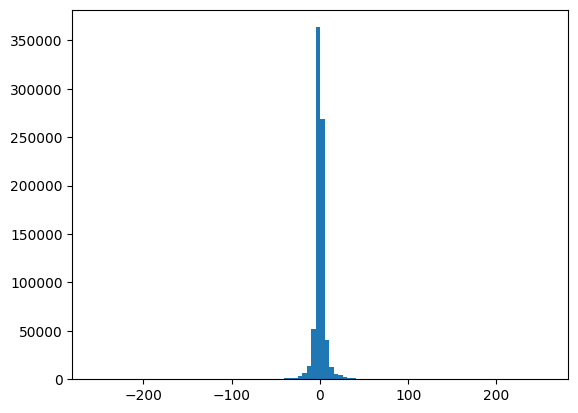

[0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 2.00000e+00 3.00000e+00 8.00000e+00 9.00000e+00 1.30000e+01 1.20000e+01
 2.30000e+01 1.60000e+01 2.30000e+01 3.20000e+01 3.90000e+01 4.30000e+01
 5.30000e+01 6.70000e+01 1.19000e+02 1.28000e+02 1.50000e+02 1.76000e+02
 2.70000e+02 2.60000e+02 3.71000e+02 4.09000e+02 5.03000e+02 6.54000e+02
 9.25000e+02 1.25300e+03 1.78200e+03 3.70200e+03 5.98400e+03 1.41580e+04
 5.15990e+04 3.63469e+05 2.68625e+05 4.07850e+04 1.25920e+04 5.82800e+03
 3.99100e+03 2.13500e+03 1.55300e+03 1.13600e+03 8.03000e+02 6.35000e+02
 5.16000e+02 3.94000e+02 2.97000e+02 2.60000e+02 1.33000e+02 1.06000e+02
 9.90000e+01 6.60000e+01 5.90000e+01 4.50000e+01 2.90000e+01 2.60000e+01
 2.10000e+01 1.90000e+01 9.00000e+00 3.00000e+00 4.00000e+00 2.00000e+00
 0.00000e+00 0.00000e+00 3.00000e+00 1.00000e+00 0.

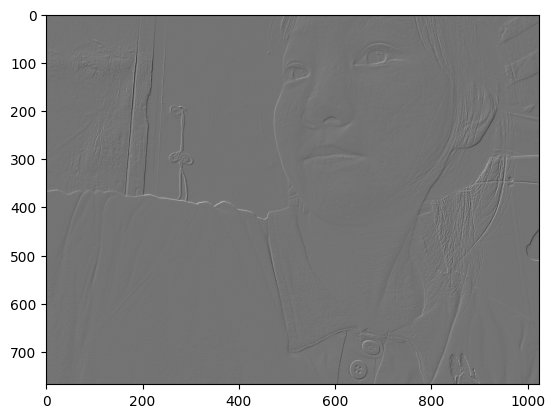

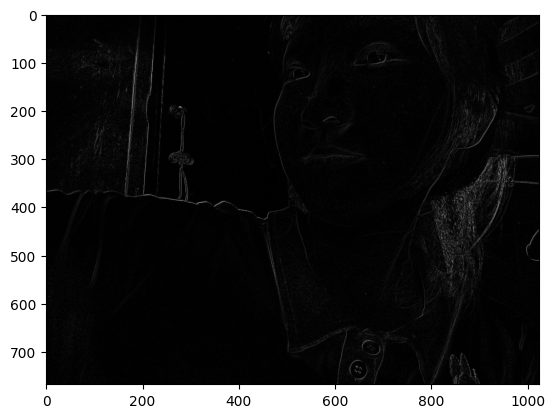

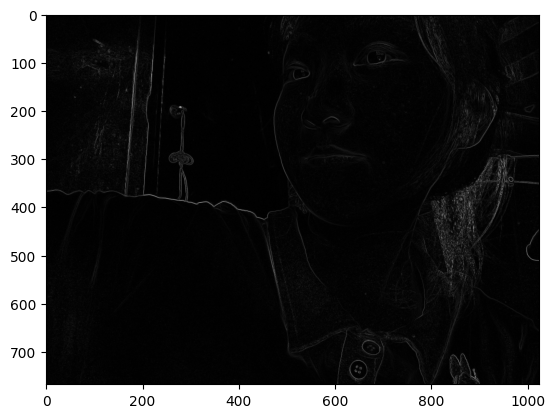

[[ 0. -3.  1. ...  9. -1. -3.]
 [ 3.  0.  2. ...  5.  2.  3.]
 [ 1.  1.  4. ...  9.  1. -3.]
 ...
 [-1. -1. -3. ... -1.  1. -3.]
 [-3. -4.  1. ...  0.  1. -3.]
 [ 3.  2.  2. ... -2. -1. -3.]]
[[-3.  0. -2. ... -5. -2. -3.]
 [ 0.  3. -1. ... -9.  1.  3.]
 [ 1.  1.  2. ... -1. -2. -1.]
 ...
 [-1. -1.  1. ... -1. -2.  1.]
 [-4. -3. -2. ...  0. -2.  2.]
 [ 2.  3. -2. ...  1. -3.  0.]]
float64
[[0 3 1 ... 9 1 3]
 [3 0 2 ... 5 2 3]
 [1 1 4 ... 9 1 3]
 ...
 [1 1 3 ... 1 1 3]
 [3 4 1 ... 0 1 3]
 [3 2 2 ... 2 1 3]]
[[3 0 2 ... 5 2 3]
 [0 3 1 ... 9 1 3]
 [1 1 2 ... 1 2 1]
 ...
 [1 1 1 ... 1 2 1]
 [4 3 2 ... 0 2 2]
 [2 3 2 ... 1 3 0]]
uint8


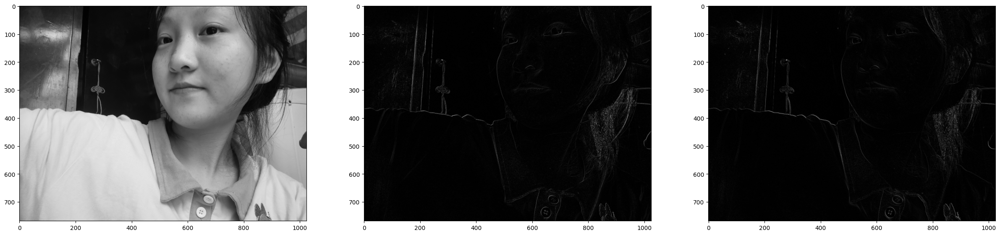

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

plt.hist(gray.ravel(),bins =256,range=[0,256])
plt.show()

kx = np.array([[-1,0],[0,1]],dtype=np.float64)
ky = np.array([[0,-1],[1,0]],dtype = np.float64)
print(kx)
print(kx.dtype)
print(ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)


n,bins,_ = plt.hist(Gx.ravel(),bins=100,range=[-255,256])
plt.show()
print(n) 
print(bins)
plt.imshow(Gx,cmap='gray')
plt.show()
plt.imshow(np.abs(Gx),cmap='gray')
plt.show()

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)
G1 = np.sqrt(Gx*Gx + Gy*Gy)
plt.imshow(G1,cmap = 'gray')
plt.show()
print(Gx)
print(Gy)
print(Gx.dtype)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2) = plt.subplots(1,3,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')

[[-1  0]
 [ 0  1]] [[ 0 -1]
 [ 1  0]]


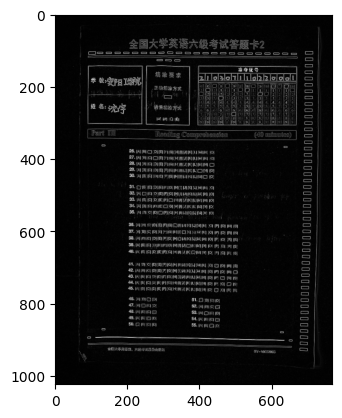

[[2 2 1 ... 0 2 2]
 [2 2 1 ... 0 2 2]
 [1 1 0 ... 2 2 1]
 ...
 [1 1 2 ... 1 1 3]
 [0 0 2 ... 0 2 2]
 [0 0 2 ... 2 2 2]]
[[-1. -2.  1. ...  0. -3.  3.]
 [ 2.  1.  1. ...  0. -1.  1.]
 [-1. -1. -1. ...  1. -2. -2.]
 ...
 [-1.  1.  2. ...  1. -1. -2.]
 [ 0.  0.  0. ... -1. -2. -4.]
 [ 0. -1.  2. ...  1. -1.  2.]]
[[-2. -1. -1. ...  0.  1. -1.]
 [ 1.  2. -1. ...  0.  3. -3.]
 [-1. -1.  0. ... -2.  2.  0.]
 ...
 [ 1. -1. -1. ... -1.  1.  4.]
 [ 0.  0. -3. ...  0. -1.  1.]
 [-1.  0. -1. ...  3.  3.  2.]]
[[1 2 1 ... 0 3 3]
 [2 1 1 ... 0 1 1]
 [1 1 1 ... 1 2 2]
 ...
 [1 1 2 ... 1 1 2]
 [0 0 0 ... 1 2 4]
 [0 1 2 ... 1 1 2]]
[[2 1 1 ... 0 1 1]
 [1 2 1 ... 0 3 3]
 [1 1 0 ... 2 2 0]
 ...
 [1 1 1 ... 1 1 4]
 [0 0 3 ... 0 1 1]
 [1 0 1 ... 3 3 2]]
uint8


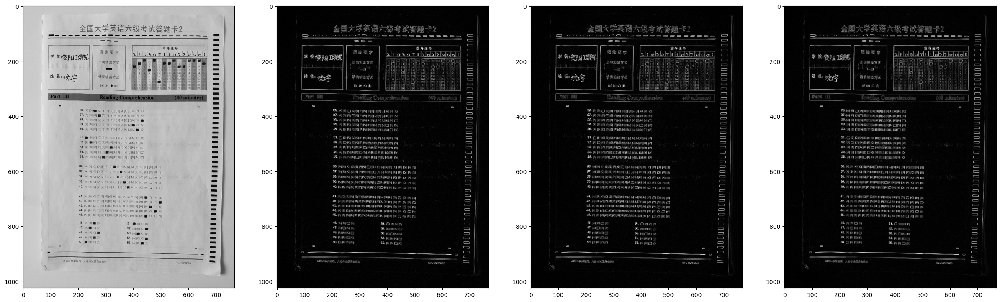

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kx = np.array([[-1,0],[0,1]])
ky = np.array([[0,-1],[1,0]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0) # y = abs(alpha * x + beta) np.abs( alpha * x + beta)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0) # Gx * 0.5 + Gy * 0.5  + bias


G1 = np.sqrt(Gx*Gx + Gy*Gy)

plt.imshow(G1,cmap = 'gray')
plt.show()

print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-2 Prewitt operator

[[-1  0  1]
 [-1  0  1]
 [-1  0  1]] [[-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]]
[[ 0. -1.  1. ... 26.  3.  0.]
 [ 0.  3.  0. ... 17.  0.  0.]
 [ 0.  4. -4. ... 17. -4.  0.]
 ...
 [ 0.  0.  6. ...  4. -2.  0.]
 [ 0.  1.  7. ...  1. -2.  0.]
 [ 0.  7.  8. ...  0. -2.  0.]]
[[  0.   0.   0. ...   0.   0.   0.]
 [  9.   8.   6. ...   6.   2.   4.]
 [  3.   3.   6. ...  11.   1.  -3.]
 ...
 [-14.  -7.  -6. ...  -3.  -4.  -4.]
 [ -3.  -2.  -2. ...  -4.  -6.  -7.]
 [  0.   0.   0. ...   0.   0.   0.]]
[[ 0  1  1 ... 26  3  0]
 [ 0  3  0 ... 17  0  0]
 [ 0  4  4 ... 17  4  0]
 ...
 [ 0  0  6 ...  4  2  0]
 [ 0  1  7 ...  1  2  0]
 [ 0  7  8 ...  0  2  0]]
[[ 0  0  0 ...  0  0  0]
 [ 9  8  6 ...  6  2  4]
 [ 3  3  6 ... 11  1  3]
 ...
 [14  7  6 ...  3  4  4]
 [ 3  2  2 ...  4  6  7]
 [ 0  0  0 ...  0  0  0]]
uint8


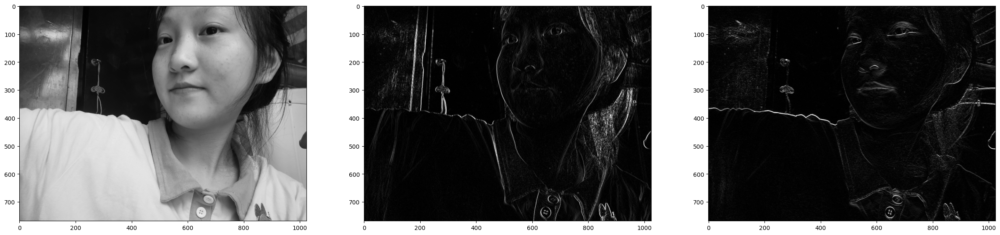

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-1,-1],[0,0,0],[1,1,1]])
kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2) = plt.subplots(1,3,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')

[[-1  0  1]
 [-1  0  1]
 [-1  0  1]] [[-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]]
[[0 0 0 ... 2 1 0]
 [1 1 2 ... 2 4 2]
 [2 4 4 ... 2 6 1]
 ...
 [0 3 8 ... 2 7 1]
 [1 4 5 ... 4 4 0]
 [0 1 6 ... 4 4 0]]
[[  0.   0.  -1. ...  -5.  -2.   0.]
 [  0.   1.  -2. ...  -4.  -4.   0.]
 [  0.  -2.  -4. ...  -2.  -9.   0.]
 ...
 [  0.   5.  -9. ...  -2. -11.   0.]
 [  0.   5.  -9. ...  -6.  -7.   0.]
 [  0.   2. -11. ...  -8.  -7.   0.]]
[[ 0.  0.  0. ...  0.  0.  0.]
 [ 2. -1. -3. ...  0. -3. -3.]
 [-3. -6. -3. ... -1. -3. -2.]
 ...
 [-1. -1. -7. ... -2. -3. -2.]
 [-2. -2. -1. ...  1.  2. -1.]
 [ 0.  0.  0. ...  0.  0.  0.]]
[[ 0  0  1 ...  5  2  0]
 [ 0  1  2 ...  4  4  0]
 [ 0  2  4 ...  2  9  0]
 ...
 [ 0  5  9 ...  2 11  0]
 [ 0  5  9 ...  6  7  0]
 [ 0  2 11 ...  8  7  0]]
[[0 0 0 ... 0 0 0]
 [2 1 3 ... 0 3 3]
 [3 6 3 ... 1 3 2]
 ...
 [1 1 7 ... 2 3 2]
 [2 2 1 ... 1 2 1]
 [0 0 0 ... 0 0 0]]
uint8


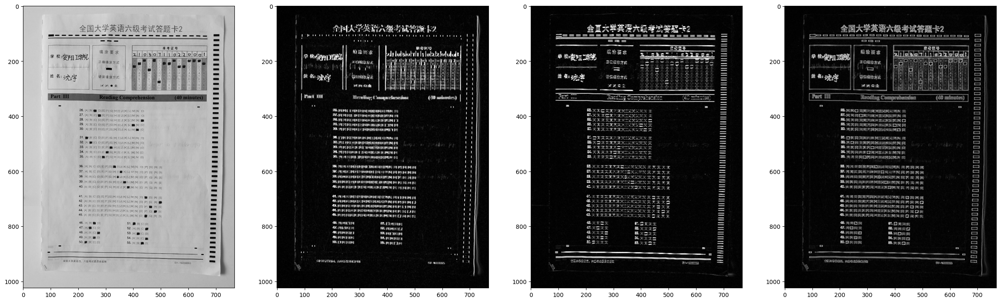

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-1,-1],[0,0,0],[1,1,1]])
kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-3 Soble operator 

[[-1  0  1]
 [-2  0  2]
 [-1  0  1]] [[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[ 0.  0.  4. ... 30.  2.  0.]
 [ 0.  2. -1. ... 28.  2.  0.]
 [ 0.  7. -6. ... 19. -5.  0.]
 ...
 [ 0. -2.  8. ...  6. -3.  0.]
 [ 0.  5. 10. ...  2. -3.  0.]
 [ 0.  6. 10. ... -2. -2.  0.]]
[[  0.   0.   0. ...   0.   0.   0.]
 [ 10.  12.   9. ...   6.   4.   4.]
 [  2.   5.   8. ...  15.   1.  -6.]
 ...
 [-18. -12.  -4. ...  -4.  -5.  -6.]
 [ -4.  -3.  -2. ...  -6.  -9.  -8.]
 [  0.   0.   0. ...   0.   0.   0.]]
[[ 0  0  4 ... 30  2  0]
 [ 0  2  1 ... 28  2  0]
 [ 0  7  6 ... 19  5  0]
 ...
 [ 0  2  8 ...  6  3  0]
 [ 0  5 10 ...  2  3  0]
 [ 0  6 10 ...  2  2  0]]
[[ 0  0  0 ...  0  0  0]
 [10 12  9 ...  6  4  4]
 [ 2  5  8 ... 15  1  6]
 ...
 [18 12  4 ...  4  5  6]
 [ 4  3  2 ...  6  9  8]
 [ 0  0  0 ...  0  0  0]]
uint8


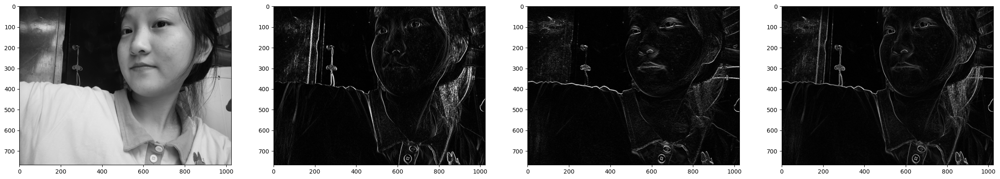

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)


G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[ 0  1  0 ...  4  0  0]
 [ 1  0  4 ...  3  4  4]
 [ 3  4  6 ...  2  8  2]
 ...
 [ 0  5 10 ...  3  9  1]
 [ 1  4  8 ...  5  5  1]
 [ 0  2  6 ...  6  4  0]]
[[  0.   2.   0. ...  -8.   0.   0.]
 [  0.   0.  -3. ...  -5.  -6.   0.]
 [  0.  -2.  -6. ...  -2. -13.   0.]
 ...
 [  0.   8. -12. ...  -2. -14.   0.]
 [  0.   5. -14. ...  -8. -10.   0.]
 [  0.   4. -12. ... -12.  -8.   0.]]
[[ 0.  0.  0. ...  0.  0.  0.]
 [ 2.  0. -5. ...  1. -2. -8.]
 [-6. -6. -6. ... -2. -3. -4.]
 ...
 [ 0. -2. -8. ... -4. -4. -2.]
 [-2. -3. -2. ...  2.  0.  2.]
 [ 0.  0.  0. ...  0.  0.  0.]]
[[ 0  2  0 ...  8  0  0]
 [ 0  0  3 ...  5  6  0]
 [ 0  2  6 ...  2 13  0]
 ...
 [ 0  8 12 ...  2 14  0]
 [ 0  5 14 ...  8 10  0]
 [ 0  4 12 ... 12  8  0]]
[[0 0 0 ... 0 0 0]
 [2 0 5 ... 1 2 8]
 [6 6 6 ... 2 3 4]
 ...
 [0 2 8 ... 4 4 2]
 [2 3 2 ... 2 0 2]
 [0 0 0 ... 0 0 0]]
uint8


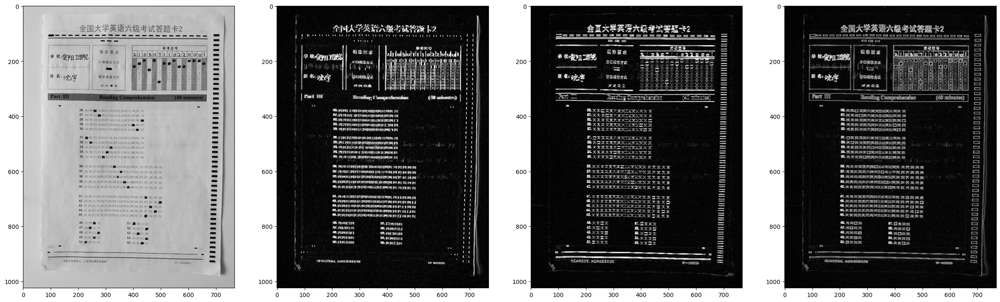

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(kx)
print(ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

## cv2.Sobel

[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[0 1 0 ... 2 1 0]
 [0 1 2 ... 1 2 2]
 [2 0 2 ... 0 2 1]
 ...
 [0 2 2 ... 1 2 0]
 [0 0 3 ... 2 2 2]
 [0 1 0 ... 2 0 0]]
[[ 0.  2.  1. ... -3.  2.  0.]
 [ 0. -1. -1. ... -1. -2.  0.]
 [ 0.  0. -2. ...  0. -4.  0.]
 ...
 [ 0.  3. -3. ...  0. -3.  0.]
 [ 0.  0. -5. ... -2. -3.  0.]
 [ 0.  2. -1. ... -4. -1.  0.]]
[[ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  1. -2. ...  1.  1. -5.]
 [-3.  0. -3. ... -1.  0. -2.]
 ...
 [ 1. -1. -1. ... -2. -1.  0.]
 [ 0. -1. -1. ...  1. -2.  3.]
 [ 0.  0.  0. ...  0.  0.  0.]]
[[0 2 1 ... 3 2 0]
 [0 1 1 ... 1 2 0]
 [0 0 2 ... 0 4 0]
 ...
 [0 3 3 ... 0 3 0]
 [0 0 5 ... 2 3 0]
 [0 2 1 ... 4 1 0]]
[[0 0 0 ... 0 0 0]
 [0 1 2 ... 1 1 5]
 [3 0 3 ... 1 0 2]
 ...
 [1 1 1 ... 2 1 0]
 [0 1 1 ... 1 2 3]
 [0 0 0 ... 0 0 0]]
uint8


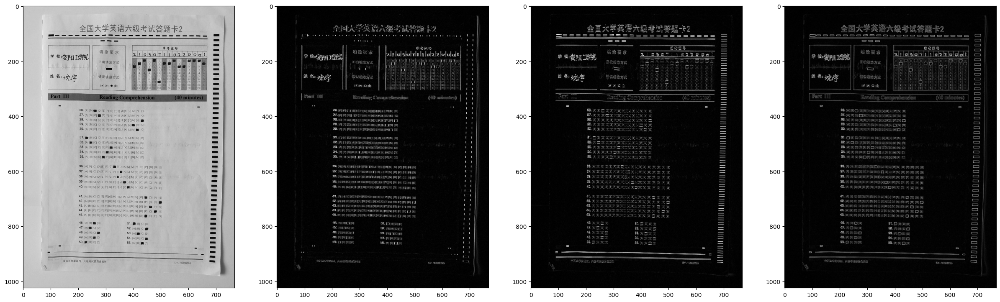

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(kx)
print(ky) 
#Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
#Gy = cv2.filter2D(gray,cv2.CV_64F,ky)
Gx = cv2.Sobel(gray,cv2.CV_64F,1,0,ksize = 1)
Gy = cv2.Sobel(gray,cv2.CV_64F,0,1,ksize = 1)


Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-8 Scharr operator

In [23]:

ky = np.array([[-3,-10,-3],[0,0,0],[3,10,3]])
kx = np.array([[-3,0,3],[-10,0,10],[-3,0,3]])
a = ky.ravel()
print(a)

[ -3 -10  -3   0   0   0   3  10   3]


[[ -3   0   3]
 [-10   0  10]
 [ -3   0   3]]
[[ -3 -10  -3]
 [  0   0   0]
 [  3  10   3]]


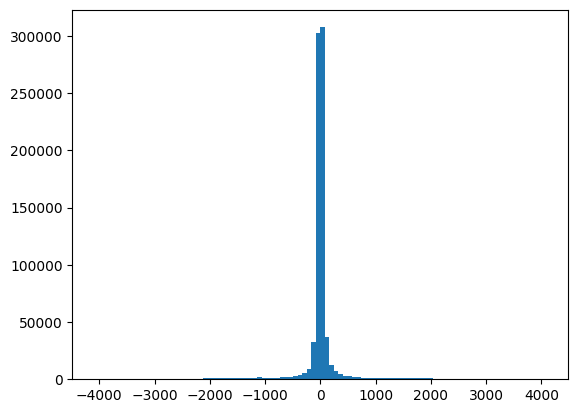

[[ 0  7  2 ... 18  4  0]
 [ 3  4 18 ... 13 14 22]
 [15 12 28 ...  8 32 10]
 ...
 [ 2 23 38 ... 13 35  3]
 [ 3 14 36 ... 21 25  9]
 [ 0 10 20 ... 26 14  0]]
3448.0 -3359.0
[[  0.  14.   4. ... -36.   8.   0.]
 [  0.  -4. -13. ... -19. -26.   0.]
 [  0.  -6. -26. ...  -6. -55.   0.]
 ...
 [  0.  36. -48. ...  -6. -54.   0.]
 [  0.  15. -62. ... -32. -42.   0.]
 [  0.  20. -40. ... -52. -28.   0.]]
[[  0.   0.   0. ...   0.   0.   0.]
 [  6.   4. -23. ...   7.  -2. -44.]
 [-30. -18. -30. ... -10.  -9. -20.]
 ...
 [  4. -10. -28. ... -20. -16.  -6.]
 [ -6. -13. -10. ...  10.  -8.  18.]
 [  0.   0.   0. ...   0.   0.   0.]]
[[ 0 14  4 ... 36  8  0]
 [ 0  4 13 ... 19 26  0]
 [ 0  6 26 ...  6 55  0]
 ...
 [ 0 36 48 ...  6 54  0]
 [ 0 15 62 ... 32 42  0]
 [ 0 20 40 ... 52 28  0]]
[[ 0  0  0 ...  0  0  0]
 [ 6  4 23 ...  7  2 44]
 [30 18 30 ... 10  9 20]
 ...
 [ 4 10 28 ... 20 16  6]
 [ 6 13 10 ... 10  8 18]
 [ 0  0  0 ...  0  0  0]]
uint8


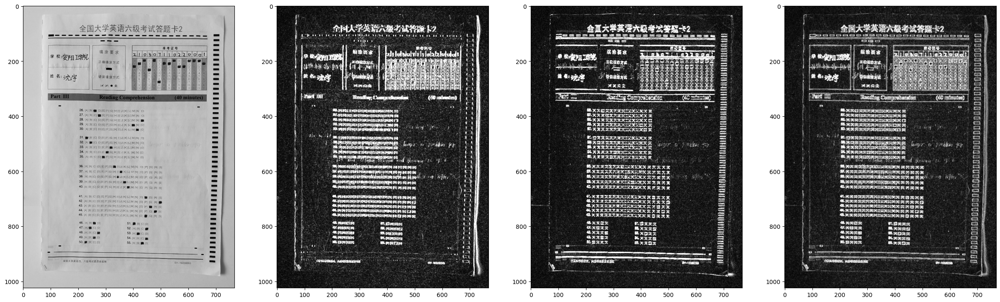

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-3,-10,-3],[0,0,0],[3,10,3]])
kx = np.array([[-3,0,3],[-10,0,10],[-3,0,3]])
print(kx)
print(ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)
#Gx = cv2.Scharr(gray,cv2.CV_64F,1,0)
#Gy = cv2.Sobel(gray,cv2.CV_64F,0,1)

plt.hist(Gx.ravel(),bins=100,range=[-255*16,255*16])
plt.show()


Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(np.max(Gx),np.min(Gx))
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs/10,cmap = 'gray')
ax2.imshow(Gy_abs/10,cmap='gray')
ax3.imshow(G,cmap = 'gray')

[[ -3   0   3]
 [-10   0  10]
 [ -3   0   3]] [[ -3 -10  -3]
 [  0   0   0]
 [  3  10   3]]
[[  0.   4.  24. ... 106.   2.   0.]
 [  0.   2.  -7. ... 128.  14.   0.]
 [  0.  33. -26. ...  65. -19.   0.]
 ...
 [  0. -14.  32. ...  26. -13.   0.]
 [  0.  31.  42. ...  10. -13.   0.]
 [  0.  14.  38. ... -14.  -6.   0.]]
[[  0.   0.   0. ...   0.   0.   0.]
 [ 34.  52.  39. ...  18.  20.  12.]
 [  2.  23.  32. ...  61.   3. -30.]
 ...
 [-70. -56.  -4. ... -16. -19. -26.]
 [-16. -13.  -6. ... -26. -39. -28.]
 [  0.   0.   0. ...   0.   0.   0.]]
[[  0   4  24 ... 106   2   0]
 [  0   2   7 ... 128  14   0]
 [  0  33  26 ...  65  19   0]
 ...
 [  0  14  32 ...  26  13   0]
 [  0  31  42 ...  10  13   0]
 [  0  14  38 ...  14   6   0]]
[[ 0  0  0 ...  0  0  0]
 [34 52 39 ... 18 20 12]
 [ 2 23 32 ... 61  3 30]
 ...
 [70 56  4 ... 16 19 26]
 [16 13  6 ... 26 39 28]
 [ 0  0  0 ...  0  0  0]]
uint8


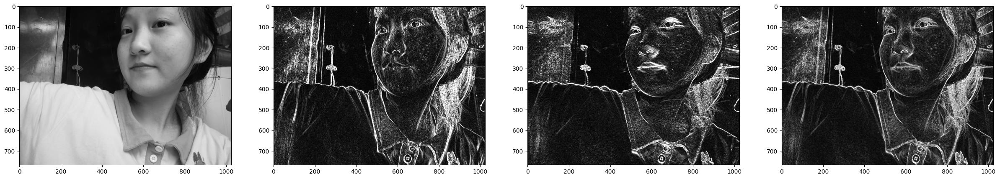

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-3,-10,-3],[0,0,0],[3,10,3]])
kx = np.array([[-3,0,3],[-10,0,10],[-3,0,3]])
print(kx,ky) 
#Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
#Gy = cv2.filter2D(gray,cv2.CV_64F,ky)
Gx = cv2.Scharr(gray,cv2.CV_64F,1,0)
Gy = cv2.Scharr(gray,cv2.CV_64F,0,1)
Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)


G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-4 Laplacian Operator

[[ 0  1  0]
 [ 1 -4  1]
 [ 0  1  0]]
[[ 2  5  1 ... 14 15  2]
 [ 7  5  0 ...  1 14  2]
 [ 5  5  8 ...  4  7  1]
 ...
 [ 6  1  6 ...  1  2  4]
 [ 7  9  9 ...  3  8  7]
 [ 8  3  6 ...  4  6  0]]


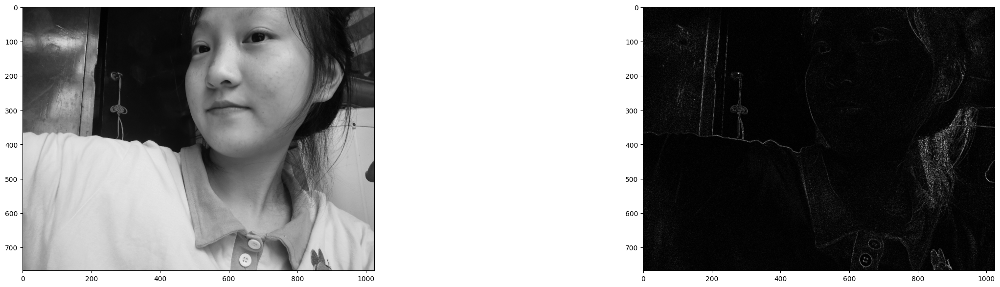

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

G = cv2.filter2D(gray,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

print(kernel)
print(G)

fig,(ax0,ax1) = plt.subplots(1,2,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(G,cmap = 'gray')


[[ 0  1  0]
 [ 1 -4  1]
 [ 0  1  0]]
[[ 8  0  1 ...  5  4 10]
 [10  4  5 ...  8  5  3]
 [ 7  6  3 ...  1  4 10]
 ...
 [ 1  4 14 ...  0  6  4]
 [ 0  1  0 ...  3  1  9]
 [ 2  6 11 ...  6  5 12]]


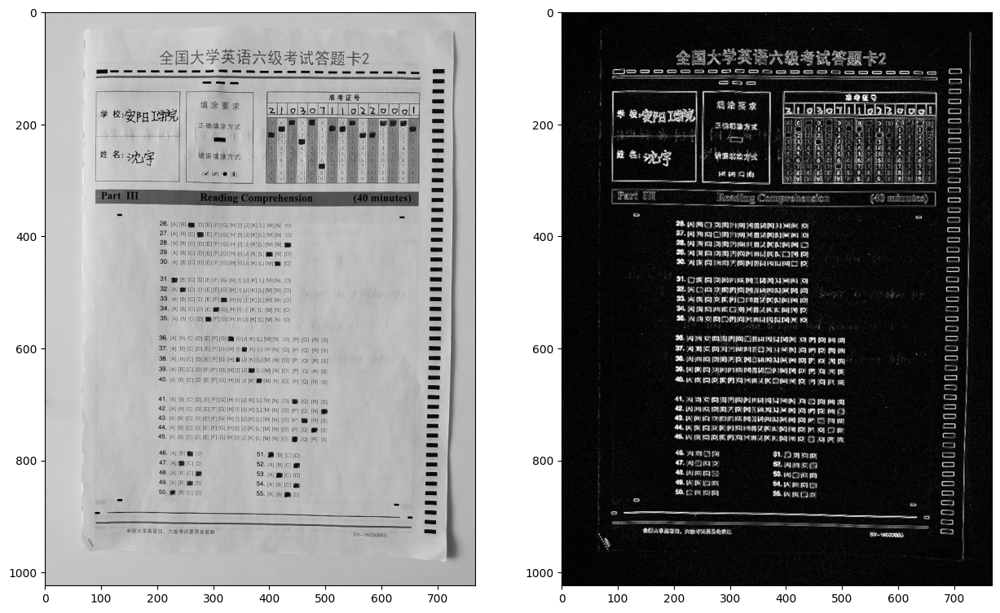

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))

gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

#G = cv2.filter2D(gray,cv2.CV_64F,kernel)

G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

print(kernel)
print(G)

fig,(ax0,ax1) = plt.subplots(1,2,figsize = (15,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(G,cmap = 'gray')


# example 9-5  first blur with gaussian then laplacian 

[[ 28  27  29 ...  91  88  90]
 [ 30  28  29 ...  89  93  91]
 [ 29  31  32 ...  91  90  90]
 ...
 [136 135 134 ... 198 199 197]
 [132 132 136 ... 197 199 196]
 [135 134 134 ... 196 196 196]]
[[ 0  1  0]
 [ 1 -4  1]
 [ 0  1  0]]
[[  2   5   1 ...  14  15 184]
 [  7   5  32 ...   1 105 255]
 [  5  37 120 ...   4   7  92]
 ...
 [  6   1   6 ... 198   2   4]
 [  7   9   9 ...   3   8   7]
 [  8   3   6 ...   4   6   0]]


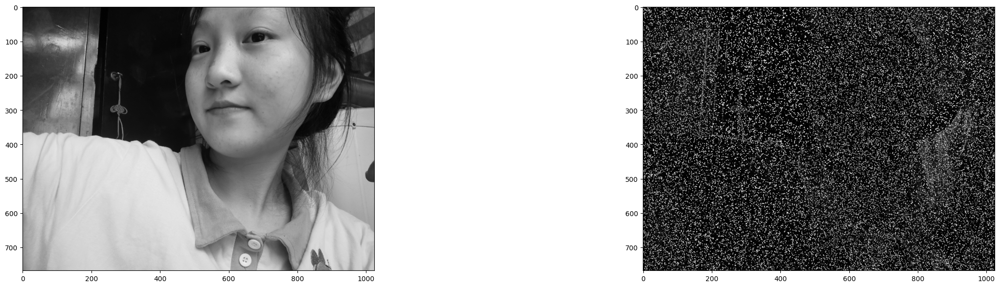

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

G = cv2.filter2D(gray_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

print(kernel)
print(G)

fig,(ax0,ax1) = plt.subplots(1,2,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(G,cmap = 'gray')


[[ 28.  27.  29. ...  91.  88.  90.]
 [  0.  28.  29. ...  89.  93.  91.]
 [ 29.  31.  32. ...   0.  90.  90.]
 ...
 [136. 135. 134. ... 198. 199. 197.]
 [132. 132. 136. ... 197. 199. 196.]
 [135. 134. 134. ...   0. 196. 196.]]


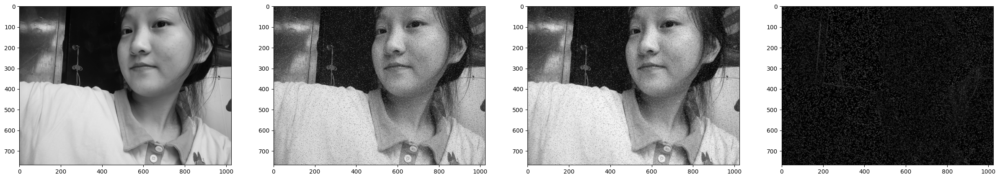

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray_noise)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

gk = cv2.getGaussianKernel(3,0)
gk = gk @ gk.T
#print(gk)

gray_remove_noise = cv2.filter2D(gray_noise,cv2.CV_64F,gk)
G = cv2.filter2D(gray_remove_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

#print(kernel)
#print(G)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(gray_noise,cmap = 'gray')
ax2.imshow(gray_remove_noise,cmap='gray')
ax3.imshow(G,cmap='gray')


[[ 28.  27.  29. ...  91.  88.  90.]
 [ 30.  28.  29. ...  89.  93.  91.]
 [ 29.  31.  32. ...  91.  90.  90.]
 ...
 [136. 135. 134. ... 198. 199. 197.]
 [255. 132. 136. ... 197. 199.   0.]
 [135. 134. 134. ... 196. 196. 196.]]


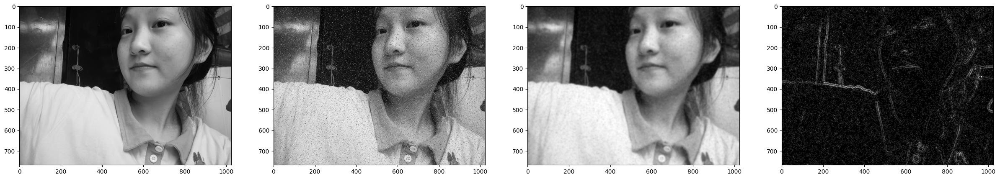

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray_noise)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

gk = cv2.getGaussianKernel(17,0)
gk = gk @ gk.T
#print(gk)

gray_remove_noise = cv2.filter2D(gray_noise,cv2.CV_64F,gk)
G = cv2.filter2D(gray_remove_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

#print(kernel)
#print(G)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(gray_noise,cmap = 'gray')
ax2.imshow(gray_remove_noise,cmap='gray')
ax3.imshow(G,cmap='gray')


[[ 28.  27.  29. ...  91.  88.  90.]
 [ 30.  28.  29. ...  89.  93.  91.]
 [ 29.  31.  32. ...  91.  90.  90.]
 ...
 [136. 135. 255. ... 198. 199. 197.]
 [132. 132. 136. ... 197. 199. 196.]
 [135. 134. 134. ... 196. 196. 196.]]


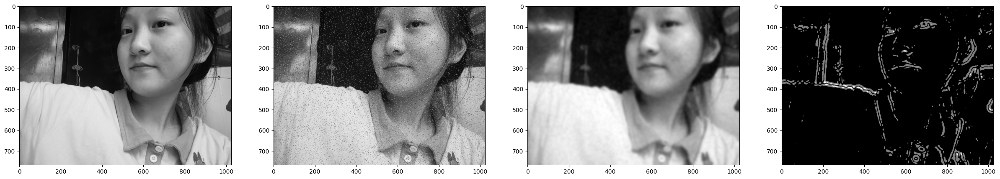

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray_noise)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

gk = cv2.getGaussianKernel(31,0)
gk = gk @ gk.T
#print(gk)

gray_remove_noise = cv2.filter2D(gray_noise,cv2.CV_64F,gk)
G = cv2.filter2D(gray_remove_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

#print(kernel)
#print(G)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(gray_noise,cmap = 'gray')
ax2.imshow(gray_remove_noise,cmap='gray')
ax3.imshow(G,cmap='gray')


请点击[此处](https://ai.baidu.com/docs#/AIStudio_Project_Notebook/a38e5576)查看本环境基本用法.  <br>
Please click [here ](https://ai.baidu.com/docs#/AIStudio_Project_Notebook/a38e5576) for more detailed instructions. 